In [1]:
import os
os.environ["CUDA_VISIBLE_DEVICES"] = "1"
os.environ["XLA_PYTHON_CLIENT_MEM_FRACTION"] = "0.9"

In [2]:
import matplotlib.pyplot as plt
%matplotlib inline
import jax

import jax.numpy as jnp
import jax.random as jr
import optax
import math

import k3d
import numpy as np
from matplotlib.colors import ListedColormap
from typing import Callable
from functools import partial

In [3]:
from implicitSurfaces.lipschitzImplicit import sdfImplicit
from sphereWalker.integrator import WoSIntegrator

In [4]:
def sphere_sdf(points: jnp.ndarray, radius: float = 1.0) -> jnp.ndarray:
    return jnp.linalg.norm(points, axis=-1) - radius

def boundary_condition(points: jnp.ndarray) -> jnp.ndarray:
    return 1.0 + 2.0 * jnp.sin(jnp.atan2(points[1], points[0]))

In [5]:
sdf = sdfImplicit(fn=partial(sphere_sdf, radius=1.0))
integrator = WoSIntegrator(
    empty_sphere_fn=sdf.empty_sphere, 
    boundary_condition_fn=boundary_condition,
    source_term_fn=lambda x: jnp.array(0.0),
    dim=2,
    level_set=0.0,
    eps=1e-3,
    max_steps=1000
)

In [6]:
def sample_sdf_rejection(key, sdf_fn: Callable, N: int, 
                         lower_bound: jnp.ndarray, 
                         upper_bound: jnp.ndarray, 
                         max_iter: int = 100):
    """
    Sample N points uniformly inside an SDF domain using rejection sampling.
    
    Args:
        key: JAX PRNGKey.
        sdf_fn: Function taking (N, D) points and returning (N,) distances.
                Points with sdf < 0 are considered 'inside'.
        N: Number of points to sample.
        lower_bound: Min corner of the sampling domain (D,).
        upper_bound: Max corner of the sampling domain (D,).
        max_iter: Safety break to prevent infinite loops if domain is empty.
        
    Returns:
        points: (N, D) array of valid points.
        valid_mask: (N,) boolean array indicating if the slot was successfully filled.
                    (Should be all True unless max_iter was reached).
    """
    
    dim = lower_bound.shape[0]

    # Initial State
    # points: The buffer we want to fill
    # mask: Boolean array tracking which slots are successfully filled
    # key: Current RNG key
    # iter_num: Counter
    init_points = jnp.zeros((N, dim))
    init_mask = jnp.zeros((N,), dtype=bool)
    init_state = (key, init_points, init_mask, 0)

    def cond_fun(state):
        _, _, mask, i = state
        # Continue if: We have empty slots AND we haven't hit max_iter
        return jnp.logical_and(
            jnp.logical_not(jnp.all(mask)), 
            i < max_iter
        )

    def body_fun(state):
        k, current_points, current_mask, i = state
        k_sub, k_next = jax.random.split(k)
        
        # 1. Sample N candidates uniformly in the bounding box
        # Note: We generate N candidates every time. 
        # This is slightly wasteful computationally but keeps shapes static for JIT.
        candidates = jax.random.uniform(k_sub, shape=(N, dim), 
                                        minval=lower_bound, maxval=upper_bound)
        
        # 2. Check SDF
        dist = sdf_fn(candidates)
        is_inside = dist < 0.0
        
        # 3. Update Logic
        # We want to accept a candidate at index 'j' IF:
        #   - The candidate is valid (is_inside[j] is True)
        #   - AND the slot was previously empty (current_mask[j] is False)
        # Otherwise, we keep the old value (current_points[j]).
        
        should_update = is_inside & (~current_mask)
        
        # Apply updates
        new_points = jnp.where(should_update[:, None], candidates, current_points)
        new_mask = current_mask | is_inside
        
        return (k_next, new_points, new_mask, i + 1)

    # Run the loop
    final_key, final_points, final_mask, final_iters = jax.lax.while_loop(cond_fun, body_fun, init_state)
    
    return final_points, final_mask

In [7]:
# Setup
key = jax.random.PRNGKey(42)
N = 100000
bounds_min = jnp.array([-1.5, -1.5])
bounds_max = jnp.array([1.5, 1.5])

# JIT compile the sampling function for speed
sample_jit = jax.jit(sample_sdf_rejection, static_argnames=['sdf_fn', 'N', 'max_iter'])

points, mask = sample_jit(key, lambda p: sphere_sdf(p, 1.0), N, bounds_min, bounds_max)

In [8]:
output = integrator.integrate_batch(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=200, init_trust_region_size=jnp.inf, steps_between_refill=1, max_active_states=1024**2)

Remaining Active States: 1048575 | Next Task Index: 1048576/20000000
Process callsed so far. f1
Remaining Active States: 1048575 | Next Task Index: 1050576/20000000
Process callsed so far. f2
Remaining Active States: 1048575 | Next Task Index: 1095308/20000000
Process callsed so far. f3
Remaining Active States: 1048575 | Next Task Index: 1165103/20000000
Process callsed so far. f4
Remaining Active States: 1048575 | Next Task Index: 1250064/20000000
Process callsed so far. f5
Remaining Active States: 1048575 | Next Task Index: 1344149/20000000
Process callsed so far. f6
Remaining Active States: 1048575 | Next Task Index: 1443945/20000000
Process callsed so far. f7
Remaining Active States: 1048575 | Next Task Index: 1546921/20000000
Process callsed so far. f8
Remaining Active States: 1048575 | Next Task Index: 1651647/20000000
Process callsed so far. f9
Remaining Active States: 1048575 | Next Task Index: 1756161/20000000
Process callsed so far. f10
Remaining Active States: 1048575 | Next

In [20]:
output = integrator.integrate_n_estimate(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=200, init_trust_region_size=jnp.inf, steps_between_refill=10, unroll_loop = False, max_active_states=1024**2)

In [17]:
output = integrator.integrate_n_estimate(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=200, init_trust_region_size=jnp.inf, steps_between_refill=10, unroll_loop = True, max_active_states=1024**2)

In [21]:
for steps_betw_refill in [1, 10, 50, 100]:
    output = integrator.integrate_n_estimate(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=200, init_trust_region_size=jnp.inf, steps_between_refill=steps_betw_refill, unroll_loop = True, max_active_states=1024**2)
    %timeit integrator.integrate_n_estimate(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=200, init_trust_region_size=jnp.inf, steps_between_refill=steps_betw_refill, unroll_loop = True, max_active_states=1024**2).nSteps.block_until_ready()

1.35 s ± 6.96 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
271 ms ± 2.1 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
503 ms ± 912 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)
905 ms ± 711 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


In [22]:
for steps_betw_refill in [1, 10, 50, 100]:
    output = integrator.integrate_n_estimate(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=200, init_trust_region_size=jnp.inf, steps_between_refill=steps_betw_refill, unroll_loop = False, max_active_states=1024**2)
    %timeit integrator.integrate_n_estimate(initial_position_batch=points, rng_key=jax.random.PRNGKey(0), n_samples=200, init_trust_region_size=jnp.inf, steps_between_refill=steps_betw_refill, unroll_loop = False, max_active_states=1024**2).nSteps.block_until_ready()

1.35 s ± 4.67 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
262 ms ± 1.54 ms per loop (mean ± std. dev. of 7 runs, 1 loop each)
493 ms ± 357 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)
894 ms ± 353 μs per loop (mean ± std. dev. of 7 runs, 1 loop each)


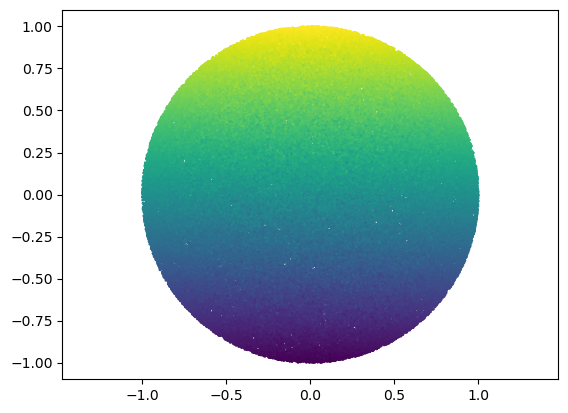

In [9]:
plt.scatter(output.position[:,0], output.position[:,1], c=output.w[:,0], s=1)
plt.axis('equal')
plt.show()